# Problem 1 - Parquet Metadata

In [1]:
import json
import pyarrow.parquet as pq
import pyarrow.fs as fs

print("Assignment 4 environment is working!")

Assignment 4 environment is working!


In [2]:
# Connect to Amazon S3
s3 = fs.S3FileSystem(region="us-east-1")

# Location of the NYC taxi Parquet file
parquet_path = (
    "bigdatateaching/nyc_tlc/trip_data/"
    "yyyy=2021/yellow_tripdata_2021-01.parquet"
)

# Read the Parquet file metadata
parquet_file = pq.ParquetFile(parquet_path, filesystem=s3)

metadata = parquet_file.metadata

# Display the metadata
print(metadata)

  created_by: parquet-cpp-arrow version 7.0.0
  num_columns: 19
  num_rows: 1369769
  num_row_groups: 1
  format_version: 1.0
  serialized_size: 10382


In [3]:
# Extract the required metadata fields
metadata_dict = {
    "created_by": metadata.created_by,
    "num_columns": metadata.num_columns,
    "num_rows": metadata.num_rows,
    "num_row_groups": metadata.num_row_groups,
    "format_version": metadata.format_version,
    "serialized_size": metadata.serialized_size
}

# Save metadata to JSON
with open("metadata.json", "w") as f:
    json.dump(metadata_dict, f, indent=4)

# Display the saved metadata
print(json.dumps(metadata_dict, indent=4))

{
    "created_by": "parquet-cpp-arrow version 7.0.0",
    "num_columns": 19,
    "num_rows": 1369769,
    "num_row_groups": 1,
    "format_version": "1.0",
    "serialized_size": 10382
}


In [4]:
# Extract compression type from the first column
compression_type = metadata.row_group(0).column(0).compression

print("Compression type:", compression_type)

# Save compression type to a text file
with open("compression_type.txt", "w") as f:
    f.write(compression_type + "\n")

Compression type: GZIP


# Problem 2 - Polars

In [5]:
import polars as pl
import subprocess
import io

In [6]:
# Examine the first 10 lines of the quazyilx dataset
result = subprocess.run(
    ["head", "-n", "10", "/tmp/quazyilx0.txt"],
    capture_output=True,
    text=True,
    check=True
)

print(result.stdout)

2000-01-01 00:00:03 fnard:7 fnok:8 cark:19 gnuck:25
2000-01-01 00:00:08 fnard:14 fnok:19 cark:16 gnuck:37
2000-01-01 00:00:17 fnard:12 fnok:11 cark:12 gnuck:8
2000-01-01 00:00:22 fnard:18 fnok:16 cark:3 gnuck:8
2000-01-01 00:00:32 fnard:7 fnok:16 cark:7 gnuck:37
2000-01-01 00:00:40 fnard:6 fnok:14 cark:3 gnuck:30
2000-01-01 00:00:47 fnard:11 fnok:10 cark:17 gnuck:7
2000-01-01 00:00:55 fnard:9 fnok:14 cark:13 gnuck:30
2000-01-01 00:00:56 fnard:10 fnok:1 cark:7 gnuck:6
2000-01-01 00:00:59 fnard:11 fnok:11 cark:12 gnuck:18



In [7]:
# Read the raw quazyilx data using Polars
df_raw = pl.read_csv(
    "/tmp/quazyilx0.txt",
    separator=" ",
    has_header=False,
    new_columns=["date", "time", "fnard", "fnok", "cark", "gnuck"],
    infer_schema_length=0
)

# Display the first five rows
print(df_raw.head())
print("Shape:", df_raw.shape)

shape: (5, 6)
┌────────────┬──────────┬──────────┬─────────┬─────────┬──────────┐
│ date       ┆ time     ┆ fnard    ┆ fnok    ┆ cark    ┆ gnuck    │
│ ---        ┆ ---      ┆ ---      ┆ ---     ┆ ---     ┆ ---      │
│ str        ┆ str      ┆ str      ┆ str     ┆ str     ┆ str      │
╞════════════╪══════════╪══════════╪═════════╪═════════╪══════════╡
│ 2000-01-01 ┆ 00:00:03 ┆ fnard:7  ┆ fnok:8  ┆ cark:19 ┆ gnuck:25 │
│ 2000-01-01 ┆ 00:00:08 ┆ fnard:14 ┆ fnok:19 ┆ cark:16 ┆ gnuck:37 │
│ 2000-01-01 ┆ 00:00:17 ┆ fnard:12 ┆ fnok:11 ┆ cark:12 ┆ gnuck:8  │
│ 2000-01-01 ┆ 00:00:22 ┆ fnard:18 ┆ fnok:16 ┆ cark:3  ┆ gnuck:8  │
│ 2000-01-01 ┆ 00:00:32 ┆ fnard:7  ┆ fnok:16 ┆ cark:7  ┆ gnuck:37 │
└────────────┴──────────┴──────────┴─────────┴─────────┴──────────┘
Shape: (1000000, 6)


In [8]:
# Transform raw data into the required structure
df = df_raw.select(
    # Combine date and time into a single datetime column
    pl.concat_str(
        [pl.col("date"), pl.col("time")],
        separator=" "
    ).str.strptime(
        pl.Datetime("us"),
        format="%Y-%m-%d %H:%M:%S"
    ).alias("date_time"),

    # Extract numeric values and convert to 32-bit integers
    pl.col("fnard").str.replace_all("fnard:", "").cast(pl.Int32),
    pl.col("fnok").str.replace_all("fnok:", "").cast(pl.Int32),
    pl.col("cark").str.replace_all("cark:", "").cast(pl.Int32),
    pl.col("gnuck").str.replace_all("gnuck:", "").cast(pl.Int32)
)

# Inspect the transformed dataframe
print(df.head())
print(df.schema)
print("Shape:", df.shape)

shape: (5, 5)
┌─────────────────────┬───────┬──────┬──────┬───────┐
│ date_time           ┆ fnard ┆ fnok ┆ cark ┆ gnuck │
│ ---                 ┆ ---   ┆ ---  ┆ ---  ┆ ---   │
│ datetime[μs]        ┆ i32   ┆ i32  ┆ i32  ┆ i32   │
╞═════════════════════╪═══════╪══════╪══════╪═══════╡
│ 2000-01-01 00:00:03 ┆ 7     ┆ 8    ┆ 19   ┆ 25    │
│ 2000-01-01 00:00:08 ┆ 14    ┆ 19   ┆ 16   ┆ 37    │
│ 2000-01-01 00:00:17 ┆ 12    ┆ 11   ┆ 12   ┆ 8     │
│ 2000-01-01 00:00:22 ┆ 18    ┆ 16   ┆ 3    ┆ 8     │
│ 2000-01-01 00:00:32 ┆ 7     ┆ 16   ┆ 7    ┆ 37    │
└─────────────────────┴───────┴──────┴──────┴───────┘
Schema({'date_time': Datetime(time_unit='us', time_zone=None), 'fnard': Int32, 'fnok': Int32, 'cark': Int32, 'gnuck': Int32})
Shape: (1000000, 5)


In [12]:
import boto3
import io

# Get the AWS account ID
sts = boto3.client("sts")
account_id = sts.get_caller_identity()["Account"]

# Define the S3 destination
bucket_name = f"assignment-polars-duckdb-{account_id}"
s3_key = "quazyilx0.parquet"

# Write the dataframe to Parquet in memory
buffer = io.BytesIO()
df.write_parquet(buffer, use_pyarrow=True)

# Upload the Parquet file to S3
s3_client = boto3.client("s3")
s3_client.put_object(
    Bucket=bucket_name,
    Key=s3_key,
    Body=buffer.getvalue()
)

print(f"Successfully uploaded to s3://{bucket_name}/{s3_key}")

Successfully uploaded to s3://assignment-polars-duckdb-723753436257/quazyilx0.parquet


In [13]:
# Verify the Parquet file exists in S3
s3_path = f"s3://{bucket_name}/{s3_key}"

result = subprocess.run(
    ["aws", "s3", "ls", s3_path],
    capture_output=True,
    text=True,
    check=True
)

# Save the output to ls.txt
with open("ls.txt", "w") as f:
    f.write(result.stdout)

print(result.stdout)

2026-10-11 18:53:05    8628899 quazyilx0.parquet



In [14]:
# Find rows where all four measurements equal -1
anomalies = df.filter(
    (pl.col("fnard") == -1) &
    (pl.col("fnok") == -1) &
    (pl.col("cark") == -1) &
    (pl.col("gnuck") == -1)
)

# Save anomalies to CSV
anomalies.write_csv("anomalies.csv")

# Display results
print("Number of anomalies:", anomalies.height)
print(anomalies.head(10))

Number of anomalies: 3
shape: (3, 5)
┌─────────────────────┬───────┬──────┬──────┬───────┐
│ date_time           ┆ fnard ┆ fnok ┆ cark ┆ gnuck │
│ ---                 ┆ ---   ┆ ---  ┆ ---  ┆ ---   │
│ datetime[μs]        ┆ i32   ┆ i32  ┆ i32  ┆ i32   │
╞═════════════════════╪═══════╪══════╪══════╪═══════╡
│ 2000-01-28 03:07:44 ┆ -1    ┆ -1   ┆ -1   ┆ -1    │
│ 2000-02-21 19:21:07 ┆ -1    ┆ -1   ┆ -1   ┆ -1    │
│ 2000-03-01 17:31:22 ┆ -1    ┆ -1   ┆ -1   ┆ -1    │
└─────────────────────┴───────┴──────┴──────┴───────┘


# Problem 3 - DuckDB

In [15]:
import duckdb
import boto3

# Get AWS account ID and construct the S3 path
account_id = boto3.client("sts").get_caller_identity()["Account"]

bucket_name = f"assignment-polars-duckdb-{account_id}"
parquet_path = f"s3://{bucket_name}/quazyilx0.parquet"

# Create DuckDB connection
con = duckdb.connect()

# Configure DuckDB for S3 access
con.execute("INSTALL httpfs;")
con.execute("LOAD httpfs;")

# Use the EC2 instance's AWS credentials
con.execute("""
    CREATE OR REPLACE SECRET s3_secret (
        TYPE s3,
        PROVIDER credential_chain
    );
""")

print("DuckDB connected successfully!")

DuckDB connected successfully!


In [16]:
# Count the number of readings per hour using DuckDB
query = f"""
SELECT
    EXTRACT(YEAR FROM date_time) AS year,
    EXTRACT(MONTH FROM date_time) AS month,
    EXTRACT(DAY FROM date_time) AS day,
    EXTRACT(HOUR FROM date_time) AS hour,
    COUNT(*) AS count
FROM read_parquet('{parquet_path}')
GROUP BY year, month, day, hour
ORDER BY year, month, day, hour
"""

# Execute the SQL query
readings_per_hour = con.execute(query).df()

# Display the results
print(readings_per_hour.head(10))
print("Number of hourly groups:", len(readings_per_hour))
print("Total readings:", readings_per_hour["count"].sum())

   year  month  day  hour  count
0  2000      1    1     0    659
1  2000      1    1     1    645
2  2000      1    1     2    658
3  2000      1    1     3    643
4  2000      1    1     4    658
5  2000      1    1     5    644
6  2000      1    1     6    646
7  2000      1    1     7    658
8  2000      1    1     8    634
9  2000      1    1     9    688
Number of hourly groups: 1527
Total readings: 1000000


In [17]:
# Save hourly reading counts to CSV
readings_per_hour.to_csv("readings_per_hour.csv", index=False)

print("Successfully saved readings_per_hour.csv")

Successfully saved readings_per_hour.csv


# Problem 4 - Advanced DuckDB

In [18]:
import duckdb
import boto3
import pandas as pd
import matplotlib.pyplot as plt

# Identify our S3 bucket
account_id = boto3.client("sts").get_caller_identity()["Account"]
bucket_name = f"assignment-polars-duckdb-{account_id}"
parquet_path = f"s3://{bucket_name}/quazyilx0.parquet"

# Connect to DuckDB
con = duckdb.connect()

# Enable S3 access
con.execute("INSTALL httpfs;")
con.execute("LOAD httpfs;")

# Authenticate using the EC2 instance's AWS credentials
con.execute("""
    CREATE OR REPLACE SECRET s3_secret (
        TYPE s3,
        PROVIDER credential_chain
    );
""")

print("Advanced DuckDB environment ready!")

Advanced DuckDB environment ready!


In [19]:
# Calculate hourly averages for the first week of January 2000
query = f"""
SELECT
    DATE_TRUNC('hour', date_time) AS hour,
    AVG(fnard) AS fnard_avg,
    AVG(fnok) AS fnok_avg,
    AVG(cark) AS cark_avg,
    AVG(gnuck) AS gnuck_avg
FROM read_parquet('{parquet_path}')
WHERE date_time >= '2000-01-01'
  AND date_time < '2000-01-08'
GROUP BY 1
ORDER BY 1
"""

hourly_avg = con.execute(query).df()

print(hourly_avg.head(10))
print("Number of hourly observations:", len(hourly_avg))

                 hour  fnard_avg   fnok_avg  cark_avg  gnuck_avg
0 2000-01-01 00:00:00   9.435508   9.400607  9.884674  23.807284
1 2000-01-01 01:00:00   9.663566   9.796899  9.615504  24.248062
2 2000-01-01 02:00:00   9.352584   9.914894  9.471125  24.782675
3 2000-01-01 03:00:00   9.930016   9.192846  8.962675  24.161742
4 2000-01-01 04:00:00   9.671733   9.600304  9.196049  24.629179
5 2000-01-01 05:00:00   9.641304  10.006211  9.501553  25.211180
6 2000-01-01 06:00:00   9.462848   9.828173  9.396285  24.948916
7 2000-01-01 07:00:00   9.565350   8.940729  9.264438  24.319149
8 2000-01-01 08:00:00   9.753943   9.276025  9.291798  25.361199
9 2000-01-01 09:00:00   9.463663   9.421512  9.722384  24.550872
Number of hourly observations: 168


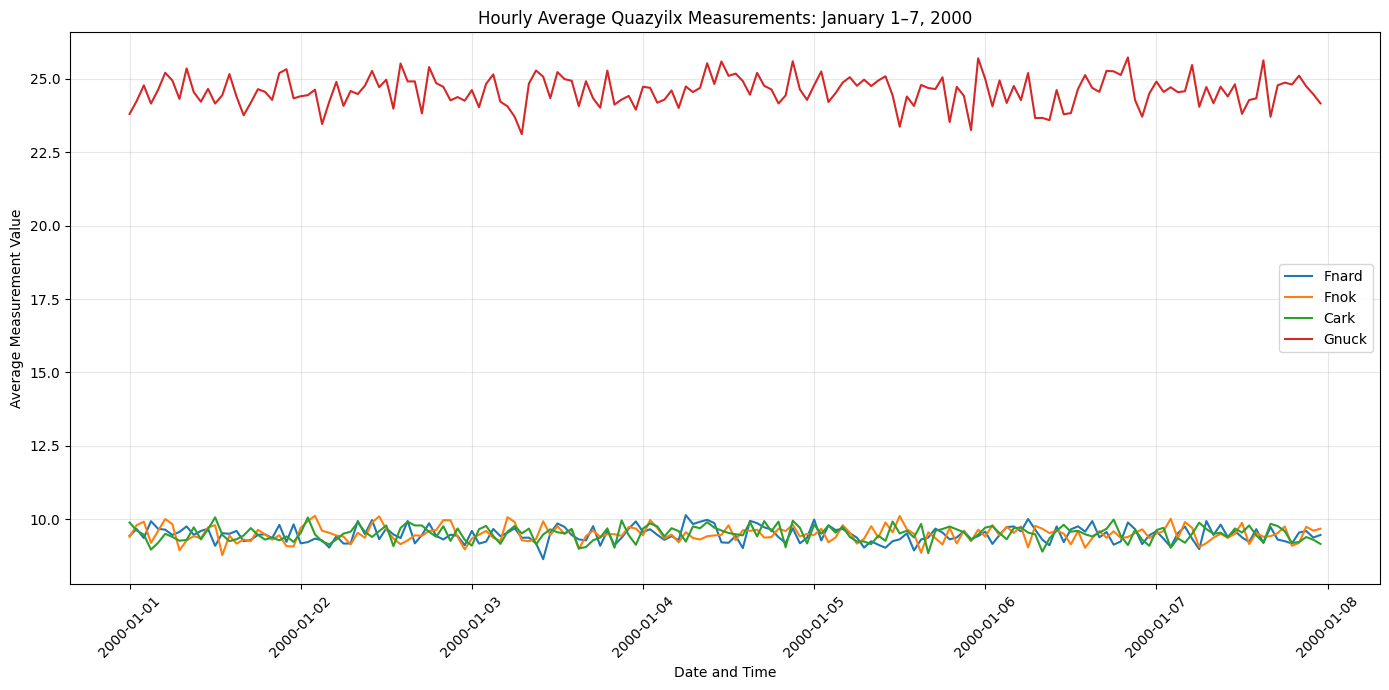

Successfully saved hourly_timeseries.png


In [20]:
# Create the hourly time-series visualization
plt.figure(figsize=(14, 7))

plt.plot(hourly_avg["hour"], hourly_avg["fnard_avg"],
         label="Fnard", linewidth=1.5)

plt.plot(hourly_avg["hour"], hourly_avg["fnok_avg"],
         label="Fnok", linewidth=1.5)

plt.plot(hourly_avg["hour"], hourly_avg["cark_avg"],
         label="Cark", linewidth=1.5)

plt.plot(hourly_avg["hour"], hourly_avg["gnuck_avg"],
         label="Gnuck", linewidth=1.5)

# Format the chart
plt.title("Hourly Average Quazyilx Measurements: January 1–7, 2000")
plt.xlabel("Date and Time")
plt.ylabel("Average Measurement Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

# Save the chart
plt.savefig("hourly_timeseries.png", dpi=300, bbox_inches="tight")

# Display the chart
plt.show()

print("Successfully saved hourly_timeseries.png")

In [21]:
# Calculate 7-day moving averages and identify high volatility

query = f"""
WITH daily_averages AS (
    SELECT
        CAST(date_time AS DATE) AS date,
        AVG(fnard) AS fnard_avg,
        AVG(fnok) AS fnok_avg,
        AVG(cark) AS cark_avg,
        AVG(gnuck) AS gnuck_avg
    FROM read_parquet('{parquet_path}')
    GROUP BY 1
),
moving_averages AS (
    SELECT
        *,
        AVG(fnard_avg) OVER (
            ORDER BY date ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
        ) AS fnard_ma7,
        AVG(fnok_avg) OVER (
            ORDER BY date ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
        ) AS fnok_ma7,
        AVG(cark_avg) OVER (
            ORDER BY date ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
        ) AS cark_ma7,
        AVG(gnuck_avg) OVER (
            ORDER BY date ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
        ) AS gnuck_ma7
    FROM daily_averages
)
SELECT
    date,
    ROUND(fnard_ma7, 2) AS fnard_ma7,
    ROUND(fnok_ma7, 2) AS fnok_ma7,
    ROUND(cark_ma7, 2) AS cark_ma7,
    ROUND(gnuck_ma7, 2) AS gnuck_ma7,
    (
        ABS(fnard_avg - fnard_ma7) > 0.5 * ABS(fnard_ma7)
        OR ABS(fnok_avg - fnok_ma7) > 0.5 * ABS(fnok_ma7)
        OR ABS(cark_avg - cark_ma7) > 0.5 * ABS(cark_ma7)
        OR ABS(gnuck_avg - gnuck_ma7) > 0.5 * ABS(gnuck_ma7)
    ) AS volatility_flag
FROM moving_averages
ORDER BY date
"""

moving_avg_df = con.execute(query).df()

print(moving_avg_df.head(10))
print("Total days analyzed:", len(moving_avg_df))
print("High volatility days:", moving_avg_df["volatility_flag"].sum())

        date  fnard_ma7  fnok_ma7  cark_ma7  gnuck_ma7  volatility_flag
0 2000-01-01       9.53      9.42      9.44      24.56            False
1 2000-01-02       9.48      9.49      9.50      24.57            False
2 2000-01-03       9.46      9.50      9.48      24.55            False
3 2000-01-04       9.49      9.51      9.52      24.60            False
4 2000-01-05       9.47      9.50      9.51      24.60            False
5 2000-01-06       9.48      9.50      9.51      24.59            False
6 2000-01-07       9.47      9.50      9.51      24.59            False
7 2000-01-08       9.47      9.51      9.51      24.56            False
8 2000-01-09       9.47      9.50      9.50      24.53            False
9 2000-01-10       9.48      9.49      9.50      24.53            False
Total days analyzed: 64
High volatility days: 0


In [22]:
# Analysis 3: Correlation between daily average measurements

query = f"""
WITH daily_averages AS (
    SELECT
        CAST(date_time AS DATE) AS date,
        AVG(fnard) AS fnard,
        AVG(fnok) AS fnok,
        AVG(cark) AS cark,
        AVG(gnuck) AS gnuck
    FROM read_parquet('{parquet_path}')
    GROUP BY 1
)
SELECT
    CORR(fnard, fnok) AS fnard_fnok,
    CORR(fnard, cark) AS fnard_cark,
    CORR(fnard, gnuck) AS fnard_gnuck,
    CORR(fnok, cark) AS fnok_cark,
    CORR(fnok, gnuck) AS fnok_gnuck,
    CORR(cark, gnuck) AS cark_gnuck
FROM daily_averages
"""

correlations = con.execute(query).df()

print("Correlation coefficients:")
print(correlations.T)

Correlation coefficients:
                    0
fnard_fnok   0.035275
fnard_cark   0.080946
fnard_gnuck -0.059726
fnok_cark   -0.011025
fnok_gnuck   0.038231
cark_gnuck   0.084474


In [23]:
# Build a correlation matrix
measurements = ["fnard", "fnok", "cark", "gnuck"]

correlation_matrix = pd.DataFrame(
    1.0,
    index=measurements,
    columns=measurements
)

# Fill in pairwise correlations
for pair, value in correlations.iloc[0].items():
    col1, col2 = pair.split("_")

    correlation_matrix.loc[col1, col2] = value
    correlation_matrix.loc[col2, col1] = value

# Save the matrix
correlation_matrix.to_csv("measurement_correlations.csv")

print("Correlation Matrix:")
print(correlation_matrix.round(4))

# Identify the strongest positive correlation
strongest_pair = correlations.iloc[0].idxmax()
strongest_value = correlations.iloc[0].max()

print(f"\nHighest positive correlation: {strongest_pair}")
print(f"Correlation coefficient: {strongest_value:.4f}")

print("\nSuccessfully saved measurement_correlations.csv")

Correlation Matrix:
        fnard    fnok    cark   gnuck
fnard  1.0000  0.0353  0.0809 -0.0597
fnok   0.0353  1.0000 -0.0110  0.0382
cark   0.0809 -0.0110  1.0000  0.0845
gnuck -0.0597  0.0382  0.0845  1.0000

Highest positive correlation: cark_gnuck
Correlation coefficient: 0.0845

Successfully saved measurement_correlations.csv


In [24]:
# Analysis 4A: Find the hour with the highest average for each measurement

query = f"""
WITH hourly_averages AS (
    SELECT
        EXTRACT(HOUR FROM date_time) AS hour,
        AVG(fnard) AS fnard_avg,
        AVG(fnok) AS fnok_avg,
        AVG(cark) AS cark_avg,
        AVG(gnuck) AS gnuck_avg
    FROM read_parquet('{parquet_path}')
    GROUP BY 1
)
SELECT
    'fnard' AS measurement,
    MAX_BY(hour, fnard_avg) AS peak_hour,
    MAX(fnard_avg) AS peak_average
FROM hourly_averages

UNION ALL

SELECT
    'fnok',
    MAX_BY(hour, fnok_avg),
    MAX(fnok_avg)
FROM hourly_averages

UNION ALL

SELECT
    'cark',
    MAX_BY(hour, cark_avg),
    MAX(cark_avg)
FROM hourly_averages

UNION ALL

SELECT
    'gnuck',
    MAX_BY(hour, gnuck_avg),
    MAX(gnuck_avg)
FROM hourly_averages
"""

peak_hours = con.execute(query).df()

print("Peak hour for each measurement:")
print(peak_hours)

Peak hour for each measurement:
  measurement  peak_hour  peak_average
0       fnard         17      9.569014
1        fnok          5      9.545982
2        cark         17      9.568407
3       gnuck         19     24.605837


In [25]:
# Analysis 4B: Find days when all four measurements peaked simultaneously

query = f"""
WITH daily_averages AS (
    SELECT
        CAST(date_time AS DATE) AS date,
        AVG(fnard) AS fnard_avg,
        AVG(fnok) AS fnok_avg,
        AVG(cark) AS cark_avg,
        AVG(gnuck) AS gnuck_avg
    FROM read_parquet('{parquet_path}')
    GROUP BY 1
),
thresholds AS (
    SELECT
        QUANTILE_CONT(fnard_avg, 0.9) AS fnard_p90,
        QUANTILE_CONT(fnok_avg, 0.9) AS fnok_p90,
        QUANTILE_CONT(cark_avg, 0.9) AS cark_p90,
        QUANTILE_CONT(gnuck_avg, 0.9) AS gnuck_p90
    FROM daily_averages
)
SELECT
    d.date,
    d.fnard_avg,
    d.fnok_avg,
    d.cark_avg,
    d.gnuck_avg
FROM daily_averages d
CROSS JOIN thresholds t
WHERE d.fnard_avg >= t.fnard_p90
  AND d.fnok_avg >= t.fnok_p90
  AND d.cark_avg >= t.cark_p90
  AND d.gnuck_avg >= t.gnuck_p90
ORDER BY d.date
"""

simultaneous_peaks = con.execute(query).df()

print("Days when all four measurements peaked simultaneously:")
print(simultaneous_peaks)

print("\nNumber of simultaneous peak days:", len(simultaneous_peaks))

Days when all four measurements peaked simultaneously:
Empty DataFrame
Columns: [date, fnard_avg, fnok_avg, cark_avg, gnuck_avg]
Index: []

Number of simultaneous peak days: 0


In [26]:
# Analysis 4C: Percentage of readings during business hours

query = f"""
SELECT
    COUNT(*) AS total_readings,
    COUNT(*) FILTER (
        WHERE EXTRACT(HOUR FROM date_time) >= 9
          AND EXTRACT(HOUR FROM date_time) < 17
    ) AS business_hour_readings,
    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE EXTRACT(HOUR FROM date_time) >= 9
              AND EXTRACT(HOUR FROM date_time) < 17
        ) / COUNT(*),
        2
    ) AS business_hours_percentage
FROM read_parquet('{parquet_path}')
"""

business_hours = con.execute(query).df()

print("Business Hours Analysis:")
print(business_hours)

Business Hours Analysis:
   total_readings  business_hour_readings  business_hours_percentage
0         1000000                  333463                      33.35


In [27]:
# Combine all time-based pattern results

pattern_results = []

# Analysis 4A: Peak hours
for _, row in peak_hours.iterrows():
    pattern_results.append({
        "analysis_type": "peak_hour",
        "measurement": row["measurement"],
        "date": None,
        "hour": int(row["peak_hour"]),
        "value": float(row["peak_average"])
    })

# Analysis 4B: Simultaneous peak days
for _, row in simultaneous_peaks.iterrows():
    pattern_results.append({
        "analysis_type": "simultaneous_peak",
        "measurement": "all_four",
        "date": str(row["date"]),
        "hour": None,
        "value": 1.0
    })

# Analysis 4C: Business hours
pattern_results.append({
    "analysis_type": "business_hours_percentage",
    "measurement": "all_readings",
    "date": None,
    "hour": None,
    "value": float(
        business_hours["business_hours_percentage"].iloc[0]
    )
})

# Explicitly record that no simultaneous peak days were found
if simultaneous_peaks.empty:
    pattern_results.append({
        "analysis_type": "simultaneous_peak_count",
        "measurement": "all_four",
        "date": None,
        "hour": None,
        "value": 0.0
    })

# Create and save the dataframe
time_patterns = pd.DataFrame(pattern_results)

time_patterns.to_csv("time_patterns.csv", index=False)

print("Time-Based Pattern Analysis:")
print(time_patterns)

print("\nSuccessfully saved time_patterns.csv")

Time-Based Pattern Analysis:
               analysis_type   measurement  date  hour      value
0                  peak_hour         fnard  None  17.0   9.569014
1                  peak_hour          fnok  None   5.0   9.545982
2                  peak_hour          cark  None  17.0   9.568407
3                  peak_hour         gnuck  None  19.0  24.605837
4  business_hours_percentage  all_readings  None   NaN  33.350000
5    simultaneous_peak_count      all_four  None   NaN   0.000000

Successfully saved time_patterns.csv
